---
title: Non-linear Reduced order modeling
subtitle: Mathematical Foundations and Numerical Implementation
license: CC-BY-4.0
github: https://github.com/agussomacal/MLbook
subject: Scientific Machine Learning
venue:
biblio:
  volume: '1'
  issue: '42'
authors:
  - name: Olga Mula
    email: o.mula@tue.nl
    corresponding: false
    orcid:
    affiliations:
      - TU/e
  - name: Agustín Somacal
    email: agustin.somacal@ec-nantes.fr
    corresponding: false
    orcid: 
    affiliations:
      - Ecole Centrale Nantes
date: 2024/08/01
math:
  '\cM': '\mathcal{M}'
  '\cL': '\mathcal{L}'
  '\R': '\mathbb{R}'
  '\E': '\mathbb{E}'
  '\span': '\text{span}'
  '\dim': '\text{dim}'
  '\argmin': '\text{arg}\,\text{min}'
abbreviations:
    MyST: Markedly Structured Text
---

# Introduction

In this Notebook you will find a practical guide into the different steps needed to solve both **forward** and **state estimation inverse** problems. To this end we will first work with _**linear** reduced order models_ to understand the basics so we can later see also ways on how to go towards **non-linear strategies** and how they can help us improve certain limitations present in linear models.

## Example PDE

We will illustrate each method by analysing their behaviour on a particular form of the stationary diffusion equation. Let $\{u:\Omega \to \R\}\in V$ be the solution to the following _partial differential equation_
$$
\label{eq:diff}
-\text{div}(a \nabla u) = 1\\
u_{\partial\Omega} = 0 
$$
defined in a square domain $\Omega = [0, 1]^2$. $a:\Omega \to \R$ is a function specifying the intensity of the diffusivity on each point of the domain. In particular we will take a simlified case in which the diffusion coefficient is piecewise constant
$$a_{|D_j} = \theta_j, \quad 1\leq j \leq 4,$$
on the four square subdomains
$$D_0 = [0, 0.5]^2, D_1 = [0.5, 1]\times[0, 0.5], D_2 = [0, 0.5]\times[0.5, 1], D_3 = [0.5, 1]^2.$$
Thus the solution $u$ depends on the $4$ parameter vector $\theta=(\theta_1,\dots,\theta_4)$ which we pick in the parameter space
$$
\label{eq:abounds}
\Theta= [a_{min}, a_{max}]^4.
$$
To gain intuition on the behaiviour of the solution $u$, which is given by the mapping $\theta \mapsto a \mapsto u$ through the diffusion equation defined above [](#eq:diff), you can play with the following widget by varying the diffusion coefficients $\theta_j$ on each subdomain.

In [6]:
# Imports
%load_ext autoreload
%autoreload 2

import sys
import os

# Add to PYTHONPATH the folders of the project so the scripts can be imported
this_file_path = os.getcwd()
project_name = "smooth-sciml"
chapter_name = "05-reduced-order-modeling"
chapter_path = os.path.abspath(os.path.join(this_file_path.split(chapter_name)[0], chapter_name))
chapter_src_path = os.path.abspath(os.path.join(chapter_path, "src"))
sys.path.insert(1, chapter_path)
sys.path.insert(1, chapter_src_path)
print(chapter_src_path)

from typing import List, Tuple, Callable

import numpy as np

from src.lib.VizUtils import plot_solutions_together
from src.lib.SolutionsManagers import SolutionsManager, SolutionsManagerFEM
from src.notebooks.functions4notebooks import *

np.random.seed(42)

# to center plots
from IPython.core.display import HTML

HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
/home/callum/Repos/GitHub/smooth-sciml/chapters/05-reduced-order-modeling/src


## Defining V space

We will generate the offline solutions with a Galerkin method, in the Finite Element Method space $V.$ The FEM method for this particular example model of PDE [](#eq:diff) is implemented in the `SolutionsManagerFEM` class. It is built as an interface so that all the complex calculations are done under the hood so we can go stright to the point of understanding how reduce order models work. However, if you are interested on going deeper you can look at the source file `src/lib/SolutionsManagers.py` where the matrices that the variational formulation issues for this problem are preassambled and then used to generate the solutions or appropiate projections.

More generally, the pipeline that we will see below can be used for other PDEs but one would need 
1. to have access to a given set of snapshots (luckily given to you by someone else)
2. or build your own solver to create those snapshots which is the case of this notebook.

In [7]:
# Object that has the implementations of how to create the solutions to the PDE + projections etc
sm = SolutionsManagerFEM(blocks_geometry=(2, 2), discretization=10, num_cores=1)
print("The space V has dimension {}".format(sm.vspace_dim))

The space V has dimension 361



- ```blocks_geometry```: how many subdomains with varying diffusion coefficients, we set $(2,2)$ but you can play with other rectangular geometries.
- ```discretization```: the number of points in the FEM discretization per dimension and per block: so if is equal to $10$ and the geometry is $(2,2)$ then $(10\cdot 2-1)^2=361=\dim(V)$ (the -1 accounts for the fact that points in the boundary do not add degrees of freedom).

The methods implemented in ```SolutionsManagerFEM``` that will be needed later for making the Reduced Order Models are the following:
- ```sm.generate_solutions(theta)```: creates a list of vectors (```np.array```), each of size $N$, corresponding to solutions of the example PDE [](#eq:diff) for the set of diffusion coefficients ```theta``` which have to be given as input to the function and in the form of ```np.array``` 3-coordinate-tensors with each row being a different parameter $\theta^i$ and the other dimensions following the shape of the selected problem block geometry {eval}`sm.blocks_geometry`.
- ```sm.evaluate_solutions(points, solutions)```: given $m$ $\R^2$ coordinate ```points``` of the domain $\Omega$ and a list of $n$ ```solutions``` in the form given by the previous method, it return an $n\times m$ matrix with the evaluations of each FEM solution on the queried points.
- ```sm.generate_fm_solutions(theta, basis)```: creates a list of vectors (```np.array```), each of size $N$, corresponding to the linear approximations of the solutions of the example PDE [](#eq:diff) given by the reduced space inserted in `basis`.

To explore more in depth how this methods work go to the [appendix](#sec:sm).

#### PDE parameters
We define the lower and upper bounds on [](#eq:abounds) for the values that diffusion coefficients can take.

In [8]:
diffusion_contrast_lower = 1e-6  # a_min
diffusion_contrast_upper = 100  # a_max

#### Define display object and parameters

In [9]:
# Define the visualizer which contains the methods to plot experiments
num_points_per_dim_to_plot = 50
visualizer = VisualizerDiffEqPiecewiseConstant(
    sm,
    diffusion_contrast_lower,
    diffusion_contrast_upper,
    max_vn_dim=19,  # Maximum number of basis elements to build reduced basis
    num_points_per_dim_to_plot=num_points_per_dim_to_plot,  # size of the plotted images
    axes_xy_proportions=(3, 3)
)

#### Explore the PDE
Explore the typical solutions for this form of the stationary diffusion equation [](#eq:diff) and gain intuition. The solution will concentrate its mass or temperature on the regions of low diffusivity. For example, you can try to set the diffusivity value $\theta_j$ of one of the subregions to $1$. You should observe that the mass has concentrated on that region.

In [11]:
# Play with piecewise constant diffusivity
visualizer.show_diffusion_coefficient_subdomains()

GridspecLayout(children=(IntSlider(value=42, continuous_update=False, description='a[0,0]:', layout=Layout(gri…

Output()

## Problem Setting

Let us define now more concretely which are the two problems that we want to solve:
- **Forward modelling simulation**: the goal is to approximate the state $u(x|\theta)$ on the whole domain $x\in \Omega$ for a given parameter $\theta$. Consider this as numerically solving the PDE of interest but faster than traditional solvers (for example finite element methods).
- **State estimation inverse problem**: also we seek to approximate the state $u(x|\theta)$ on the whole domain, however, this time we don't know the parameter $\theta$. Instead we have access to point measurements $u(x^i|\theta)$ at given (or chosen) points in the domain $x^1,\dots,x^m\in \Omega$. Think of this as having placed sensors on the system under study or having compressed the full state for storage or transmission.

# Linear models

The idea behind linear methods to solve the state estimation problem is to construct a basis of $n$ functions $\phi_j:\Omega \to \R$ so that we can write the approximation to state $u$ as a linear combination
$$
\label{eq:linmethod}
u(x)\approx \tilde u(x) = \sum_{j=1}^n c_j\phi_j(x).
$$

This basis is build beforehand in an **_offline stage_** as follows:
1) **Compute $N$ solutions** (snapshots) $u^1=u(\cdot,\theta^1), \dots, u^N=u(\cdot, \theta^N)$ from a chosen set of parameters $\{\theta^1, \dots ,\theta^N\}\in \Theta^N$.

2) Create a **reduced basis** whose span defines a subspace $V_n\in V$ of dimension $n\ll N$ using the $N$ precomputed snapshots. Here $V$ is the space of functions where the solutions $u$ to the PDE and their approximations live in.

    Different strategies are possible depending on the optimality we are seeking:
    - Pick randomly (fast to compute): This new space is generated by randomply sampling $n$ solutions from $\{u^1,\dots,u^N \}.$
    - Greedy method (optimal with respect to $L_{\infty}$): This new space is generated by iteratively picking a solution from $\{u^1,\dots,u^N \}$ that is "farther" from the sub-space build until now.
    - PCA (optimal with respect to $L_{2}$): performing an SVD decomposition of the $N$ snapshots and keeping the first $n$ leading eigenvectors.

Having such a basis then the question that remains is how to find the coefficients $c_j$ on [](#eq:linmethod) given a parameter $\theta$ (**forward modelling**) or a set of measurements $(x^i, u(x^i))$ (**inverse problem**). This is done in the **_online stage_** where

3) **Measurements or parameters**:
    - We need a given parameter vector $\theta$ or
    - $m$ observations $u(x^i,\theta)$ (+noise), $1\leq i \leq m$, of a solution $u(\cdot,\theta)$ whith unknown parameter $\theta$.

4) **State estimation**: construct an approximation $\tilde u\in V_n$ of $u(\cdot,\theta)$ based on the information given (parameters or measurements).

5) **Error analysis**: to understand how our choice of basis elements and their number $n$ may affect the approximations we compute the error $\|\tilde u- u(\cdot,\theta)\|_{L^2}$ and study its behaviour.



## _Offline stage_

### 1) Compute offline solutions

#### Solution sampling method

To create our offline solutions we need to sample the parameter space by giving $N$ values of the parameters $\theta$. This can be done in many ways:

1. Uniformly sampling $\theta_i \sim U[a_{min}, a_{max}]$.
2. Making a grid of the four dimensional space $\Theta$.
3. Log-uniform sample $\theta \in \Theta$.
4. ...

The choice may impact the reduced space we will generate afterwards, and the solutions were we are going to test.


In [12]:
def solution_sampling_method_uniform(N, diffusion_contrast_lower, diffusion_contrast_upper, num_blocks) -> np.ndarray:
    """
    return:
    - array of shape (N, number_of_blocks)
    """
    return np.random.uniform(diffusion_contrast_lower, diffusion_contrast_upper, size=(N, num_blocks))


def solution_sampling_method_grid(N, diffusion_contrast_lower, diffusion_contrast_upper, num_blocks) -> np.ndarray:
    # creat the grid
    params = np.array(list(map(np.ravel, np.meshgrid(*[np.linspace(diffusion_contrast_lower, diffusion_contrast_upper,
                                                                   num=int(np.ceil(
                                                                       N ** (1 / num_blocks))))] * num_blocks)))).T
    # randomly choose n
    ix = np.random.choice(len(params), size=N, replace=False)
    return params[ix, :]

In [13]:
solution_sampling_method = solution_sampling_method_uniform

#### Compute solutions

In [14]:
number_of_solutions = 200  # N

In [15]:
%%time
diffusion_coefficients = solution_sampling_method(number_of_solutions, diffusion_contrast_lower,
                                                  diffusion_contrast_upper, np.prod(sm.blocks_geometry))
diffusion_coefficients = diffusion_coefficients.reshape((-1,) + sm.blocks_geometry)  # shape: N x 2 x 2 = 200 x 2x 2
solutions = sm.generate_solutions(diffusion_coefficients)  # shape: N x dim(V) = 200 x 361

CPU times: user 1.19 s, sys: 0 ns, total: 1.19 s
Wall time: 240 ms


## Visualize solutions
We pick for example the first $4$ solutions from the solutions snapshots matrix `solutions[:4]` and visualize their contour plots and print their corresponding parameters $\theta$.

[[[73.19939445 59.86584882]
  [37.45401251 95.07143069]]

 [[ 5.80836216 86.61761471]
  [15.60186489 15.59945288]]

 [[ 2.05845041 96.99098525]
  [60.11150157 70.80725807]]

 [[18.18249754 18.3404518 ]
  [83.24426425 21.23391186]]]


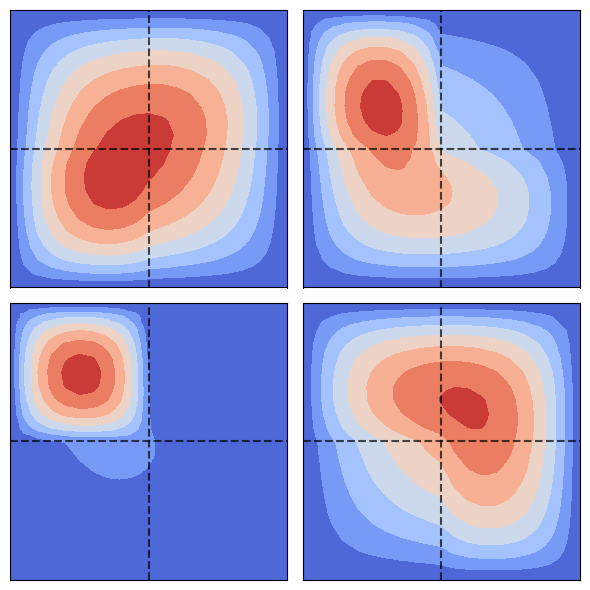

In [16]:
print(diffusion_coefficients[:4][:, ::-1])
plot_solutions_together(
    sm,
    diffusion_coefficients=diffusion_coefficients[:4][:, ::-1],
    solutions=solutions[:4],
    num_points_per_dim_to_plot=100,
    contour_levels=7,
    colorbar=False,
    axes_xy_proportions=visualizer.axes_xy_proportions
)


### 2) Generate Reduced Basis

Now we are going to create the reduced basis $V_n = \span\{\phi_1, \dots , \phi_n \}$. For that we will need the previously $N$ precomputed offline solutions and a method to effectively create this reduced basis subspace.


1. **Pick randomly**: a simple way is just to choose randomly $n$ elements from the $N$ snapshots.
2. **Greedy**: Use the greedy algorithm to incrementally create a basis that minimizes the $L_\infty$ norm over the set of $N$ precomputed solutions.
3. **PCA (Principal Component Analysis)**: other method can be to do PCA with the $N$ solutions and choose the first eigenvectors to create our basis. Note that in this case the base elements will probably not be solutions to the PDE. This method tries to minimize the $L_{2}$ norm.

In [17]:
# Scheme for a generic reduced_basis_generator method.
def reduced_basis_generator(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int,
                            *args, **kwargs) -> List[np.ndarray]:
    """

    solutions_offline: List of solutions precalculated in an offline stage: shape = (N, dim(V)).
    number_of_reduced_base_elements: n

    The output is a list of n vectors forming the basis: shape = (n, dim(V)).
    """
    ...
    return basis


def reduced_basis_generator_first_n(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int) -> List[
    np.ndarray]:
    # if the original offline solutions are random this will also be random.
    return solutions_offline[:number_of_reduced_base_elements]

#### Exercise

Implement the following algorithms for building the reduced basis:
- **Uniformly random**
- **PCA**
- **greedy** .

In [18]:
def reduced_basis_generator_random(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int,
                                   seed=42) -> List[np.ndarray]:
    np.random.seed(seed)
    # TO IMPLEMENT
    ...
    return basis


def reduced_basis_generator_pca(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int) -> List[
    np.ndarray]:
    # hint: look at PCA from sklearn library or svd from numpy and scipy.
    # TO IMPLEMENT
    ...
    return basis


def reduced_basis_generator_greedy(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int) -> List[
    np.ndarray]:
    # hint:
    # add the vector (solution) with maximum distance to the actual space by calculating the differences
    # between the solutions and the projections to the actual space.
    # For the projection solve the least square problem, you can use np.linalg.lstsq
    # TO IMPLEMENT$N=
    ...
    return basis

:::{admonition} If you are blocked 
:class: tip
Look at the following tips tips!
:::

:::{note} For ```reduced_basis_generator_random```
:class: dropdown
Take a look at ```random.choice``` from **numpy**.
:::


:::{note} For ```reduced_basis_generator_pca```
:class: dropdown
Take a look at ```StandardScaler``` and ```PCA``` from **sklearn** library.
:::

:::{note} For ```reduced_basis_generator_greedy```
:class: dropdown
Take a look at ```linalg.lstsq``` and ```argmax``` from **numpy** library.

Also, look at ```sm.l2norm``` and ```sm.H10norm``` from the ```SolutionManagerFEM``` instantiated object ```sm``` if you don't want to implement them.
:::

#### Solutions to Reduced Basis generators methods:

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# ---------- random algorithm ---------- #
def reduced_basis_generator_random(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int,
                                   seed=42) -> List[np.ndarray]:
    np.random.seed(seed)
    chosen_indexes = np.random.choice(len(solutions_offline), size=number_of_reduced_base_elements, replace=False)
    return [solutions_offline[ix] for ix in chosen_indexes]


# ---------- pca algorithm ---------- #
def reduced_basis_generator_pca(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int) -> List[
    np.ndarray]:
    transformer = StandardScaler(with_mean=True, with_std=True)  # to center by mean and scale by variance.
    # the mean and std is taken along the columns which means on each of the dimensions of the V space.
    basis = PCA(n_components=number_of_reduced_base_elements).fit(
        transformer.fit_transform(solutions_offline)).components_
    # we need to come back to the original space
    return transformer.inverse_transform(basis)


def reduced_basis_generator_pca_noznorm(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int) -> \
        List[np.ndarray]:
    return PCA(n_components=number_of_reduced_base_elements).fit(solutions_offline).components_


# ---------- greedy algorithm ---------- #
def get_function_norm(norm="l2"):
    """
    Get a function that calculates the desired norm (l2 or h10) when applied on a list of elements of the V space.
    """
    if norm == "l2":
        f_norm = sm.l2norm
    elif norm == "h10":
        f_norm = sm.H10norm
    else:
        raise Exception(f"Norm {norm} not implemented.")
    return f_norm


assert get_function_norm("l2") == sm.l2norm


def reduced_basis_generator_greedy(solutions_offline: List[np.ndarray], number_of_reduced_base_elements: int,
                                   function_norm: Callable) -> List[np.ndarray]:
    basis = [solutions_offline[np.argmax(function_norm(solutions_offline), axis=0)]]
    for _ in range(1, number_of_reduced_base_elements):
        x = np.linalg.lstsq(np.transpose(basis), np.transpose(solutions_offline), rcond=None)[0]
        next_element = np.argmax(function_norm((np.transpose(solutions_offline) - np.transpose(basis) @ x).T))
        basis.append(solutions_offline[next_element])
    return basis

In [20]:
reduced_basis_dict = {
    "PCA": reduced_basis_generator_pca(solutions, visualizer.max_vn_dim),
    "PCA_no_scale": reduced_basis_generator_pca(solutions, visualizer.max_vn_dim),
    "Greedy_l2": reduced_basis_generator_greedy(solutions, visualizer.max_vn_dim,
                                                function_norm=get_function_norm("l2")),
    "Greedy_h10": reduced_basis_generator_greedy(solutions, visualizer.max_vn_dim,
                                                 function_norm=get_function_norm("h10")),
    "Random": reduced_basis_generator_random(solutions, visualizer.max_vn_dim)
}

# **_Online stage_**: Forward modeling

## 3a) **Parameters**
We are given a set of parameters $\theta_i$ for which we want to calculate an approximation to the corresponding solution $u_i=u(x,\theta_i)$. To exemplify we take all the {eval}`number_of_solutions` parameters used for calculating the $N$ stapshots.

## 4) **Forward simulation**

The forward problem can be solved vie the Galerkin projection whose expresion is obtained after appliying the variational formulation on [](#eq:diff):
$$
\label{eq:varform}
\int_\Omega a \nabla u \nabla v &= \int_\Omega v\\
$$
Instead of writing the approximation [](#eq:linmethod) using the full FEM basis, $\phi_i$ with $i=1\dots \text{dim}(V)$ consisting on the {eval}`sm.vspace_dim` P1 elements, we take the reduced basis that only counts $n\ll N$ elements resulting in a linear system of $n\times n$ instead of $N\times N$ as in FEM. Then we have that
$$
\sum_{i=1}^n \int_\Omega a c_i \nabla \phi_i \nabla \phi_j &= \int_\Omega \phi_j \notag\\
\sum_{k=1}^4 \theta_k  \sum_{i=1}^n  c_i \int_\Omega \nabla \phi_i \nabla \phi_j &= \int_\Omega \phi_j \notag\\
\left( \sum_{k=1}^4 \theta_k A_k \right) c &= B \notag \\
A c &= B \\
\label{eq:linsystem}
$$
where $A_k \in \R^{n\times n}$ are the mass matrices associated to each subdomain $k$ given the basis $V_n$ while $A \in \R^{n\times n}$ is the resulting sum of the {eval}`np.prod(sm.blocks_geometry)`. $B\in \R^n$ is the vector associated to the source term and $c\in \R^n$ the vector of coeficients that yields the approximation [](#eq:linmethod). This are found by solving the last linear system on [](#eq:linsystem).

To generate the forward simulation solutions the interface of `SolutionManagerFEM` provides a method `sm.generate_fm_solutions(theta, basis)` which only needs the list of parameters $\theta$ to query and the chosen basis $V_n$ as a `np.array` of size $(n, \text{dim}(V))=${eval}`(visualizer.max_vn_dim,sm.vspace_dim)`.


We can now compare the difference in computation time, visualize the approximations and analyse their error and convergence towards the true solution.

In [21]:
%%timeit
sm.generate_fm_solutions(theta=diffusion_coefficients, basis=reduced_basis_dict["PCA"])

11.5 ms ± 83.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [22]:
%%timeit
sm.generate_solutions(theta=diffusion_coefficients)

206 ms ± 4.14 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Of course, having a basis of {eval}`visualizer.max_vn_dim` against the FEM one of {eval}`sm.vspace_dim` give a speed up in computation time of more than an order of magnitude due to the reduced size of the new linear system whose complexity is quadratic in the number of basis elements $n$.

In [23]:
visualizer.show_forward_problem_approximations(reduced_basis_dict)

GridspecLayout(children=(GridspecLayout(children=(IntSlider(value=42, continuous_update=False, description='a[…

Output()

In [24]:
visualizer.show_forward_problem_convergence(
    theta=diffusion_coefficients,
    solutions=solutions,
    reduced_basis_dict=reduced_basis_dict,
    max_vn_dim=10
)

GridspecLayout(children=(Dropdown(description='Error metric: ', layout=Layout(grid_area='widget001'), options=…

Output()

In [25]:
import warnings
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, LassoCV, MultiTaskLassoCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from src.lib.SolutionsManagers import orthonormalize_base

sklearn_models = {
    "Poly2 Lasso": Pipeline([("poly", PolynomialFeatures(degree=2)), ("lasso", MultiTaskLassoCV())]),
    "Lasso": LassoCV(),
    "Random Forest": RandomForestRegressor(),
}


def offline_fit(diffusion_coefficients, basis, n_linear, n_nonlinear, sklearn_model):
    n = n_linear + n_nonlinear
    c = sm.get_Vn_coeffs(theta=diffusion_coefficients, basis=basis)
    cvar = np.var(c, axis=0)
    model = sklearn_model
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(c[:, :n_linear] / cvar[:n_linear], c[:, n_linear:n] / cvar[n_linear:n])

    def online_predictor(new_theta):
        c = sm.get_Vn_coeffs(theta=new_theta, basis=basis[:n_linear])
        c_non_linear = model.predict(c / cvar[:n_linear]).reshape((-1, n - n_linear)) * cvar[n_linear:n]
        approx_solution = np.einsum("id,dj->ij", np.hstack((c, c_non_linear)), basis[:n])
        return approx_solution

    return online_predictor


sklearn_models = {
    "Poly2": Pipeline([("poly", PolynomialFeatures(degree=2)), ("lasso", LassoCV())]),
    "RF1": Pipeline([("poly", PolynomialFeatures(degree=1)), ("RF", RandomForestRegressor())]),
}


def offline_fit(diffusion_coefficients, basis, n_linear, n_nonlinear, sklearn_model):
    solutions = sm.generate_solutions(diffusion_coefficients)
    c = sm.get_Vn_coeffs(theta=diffusion_coefficients, basis=basis[:n_linear])
    linear_model = c @ basis[:n_linear]
    model = sklearn_model
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(c, np.mean(solutions - linear_model, axis=1))

    def online_predictor(new_theta):
        c = sm.get_Vn_coeffs(theta=new_theta, basis=basis[:n_linear])
        linear_model = c @ basis[:n_linear]
        return model.predict(c).reshape((-1, 1)) + linear_model

    return online_predictor

In [26]:
visualizer.show_forward_problem_non_linear_approximations(diffusion_coefficients, reduced_basis_dict, sklearn_models,
                                                          offline_fit)

GridspecLayout(children=(GridspecLayout(children=(IntSlider(value=42, continuous_update=False, description='a[…

Output()

In [27]:
visualizer.show_forward_problem_non_linear_convergence(diffusion_coefficients, solutions, reduced_basis_dict,
                                                       sklearn_models, offline_fit, max_vn_dim=10)

GridspecLayout(children=(Select(description='Reduced Basis: ', layout=Layout(grid_area='widget001'), options=(…

Output()

# **_Online stage_**: Inverse problems

## 3b) **Measurements**

Now we are ready to face a "real world" problem which consist on measuring (possibly with noise) our system at some points. These measurements can be specifically chosen points or just random observations. So we need to specify how these $m$ observations are going to be obtained:
1. Sampling uniformly random $m$ points in the domain.
2. Measures at points placed on a grid.
3. Sample only in one of the quadrants.
4. Adding more samples near the intersections of quadrants.
5. Sample randomly according to some other distribution.
6. Is there an optimal sampling strategy? [A. Cohen; G. Migliorati. Optimal weighted least-squares methods. The SMAI Journal of computational mathematics, Volume 3 (2017), pp. 181-203.](https://smai-jcm.centre-mersenne.org/articles/10.5802/smai-jcm.24/) [M. Dolbeault, PhD thesis: Optimal Sampling and Model Order Reduction](https://cloud.ljll.math.upmc.fr/owncloud/index.php/s/xuVVzqBNeutOKpa)

#### Define measurements sampling method

In [28]:
def measurements_sampling_method(number_of_measures: int, xlim: Tuple[float, float],
                                 ylim: Tuple[float, float]) -> np.ndarray:
    """
    Given the number_of_measures=m and the boundaries of the domain xlim, ylim
    return a list of m points [(x1, y1), ... (xm, ym)] sampeled from the domain where measurements will be taken (by some kind of sensor)
    measurement_points  shape = (m, 2)
    """

    ...

    return measurement_points

#### Exercise

Implement methods to sample m points in the domain which will be the sensor locations.
- sample **uniformly random**
- sample on a **grid**

In [29]:
def measurements_sampling_method_uniform(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    np.random.seed(seed)
    # TO IMPLEMENT

    ...

    return measurement_points


def measurements_sampling_method_grid(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    n_per_dim = int(np.ceil(np.sqrt(number_of_measures)))
    # TO IMPLEMENT

    ...

    return measurement_points


#_______________________________________________
# More exercises
def measurements_sampling_method_sobol_points(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    # TO IMPLEMENT

    return measurement_points


def measurements_sampling_method_latin_square(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    # TO IMPLEMENT

    return measurement_points


:::{admonition} If you are blocked 
:class: tip
Look at the following tips tips!
:::

:::{note} For ```measurements_sampling_method_uniform```
:class: dropdown
Take a look at `random.uniform` and `hstack` from **numpy**.
:::

:::{note} For ```measurements_sampling_method_grid```
:class: dropdown
Take a look at ```meshgrid``` from **numpy** library and subsample with some seed to get a fixed number of points to fair comparison.
:::

:::{note} For ```measurements_sampling_method_sobol_points```
:class: dropdown
Take a look at `qmc.Sobol` from **scipy.stats** library.
:::

:::{note} For ```measurements_sampling_method_latin_square```
:class: dropdown
- Shuffle the numbers from $1$ to $m$ two times: one for the rows another for the columns.
- This gives the center coordinates (when properly normalized to the PDE domain $[0, 1]$) of entries that do not share rows or columns.
- Add a `random.uniform` perturbation of the size of the cell $1/m$.
:::

:::{note} For ```inverse_christoffel_function```
:class: dropdown
- Orthonormalize the reduced basis. You can use `orthonormalize_base` from `src.lib.SolutionsManager` script or check `linalg.qr` from **numpy** library.
- Evaluate the orthonormalized basis in the given input points (obtained from a grid).
- Calculate the weights as $w(x_j) = \sum_i \phi(x_j)^2$ with $\phi_i$ the orthonormalized reduced basis.
:::

:::{note} For ```measurements_sampling_method_optimal```
:class: dropdown
- Generate a fine grid of the domain.
- Calculate the weights with the previous function.
- Sample $m$ points of the grid with `random.choice` from **numpy** using as weighting probability the weights obtained from `inverse_christoffel_function`.
:::

#### Solutions to excersice on sampling measurements

In [30]:
def measurements_sampling_method_uniform(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    np.random.seed(seed)
    return np.hstack((np.random.uniform(*xlim, size=(number_of_measures, 1)),
                      np.random.uniform(*ylim, size=(number_of_measures, 1))))


def measurements_sampling_method_grid(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    n_per_dim = int(np.ceil(np.sqrt(number_of_measures)))
    x, y = np.meshgrid(*[np.linspace(*xlim, num=n_per_dim + 2)[1:-1],
                         np.linspace(*ylim, num=n_per_dim + 2)[1:-1]])
    measurement_points = np.concatenate([x.reshape((-1, 1)), y.reshape((-1, 1))], axis=1)

    # keep only m points.
    np.random.seed(seed)
    ix = np.random.choice(len(measurement_points), size=number_of_measures, replace=False)
    return measurement_points[ix]


from scipy.stats import qmc


def measurements_sampling_method_sobol_points(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    # sobol points
    measurement_points = qmc.Sobol(d=2, scramble=True).random_base2(m=int(np.ceil(np.log2(number_of_measures))))
    # translate and shrink to be inside the domain
    measurement_points[:, 0] = measurement_points[:, 0] * (np.diff(xlim)) + xlim[0]
    measurement_points[:, 1] = measurement_points[:, 1] * (np.diff(ylim)) + ylim[0]
    # get exactly number_of_measures quantity
    return measurement_points[np.random.choice(len(measurement_points), size=number_of_measures, replace=False)]


def measurements_sampling_method_latin_square(number_of_measures, xlim, ylim, seed=42, **kwargs) -> np.ndarray:
    # choose points in a matrix so no one share rows nor columns with respect to others.
    measurement_points = np.transpose([np.random.choice(number_of_measures, size=number_of_measures, replace=False),
                                       np.random.choice(number_of_measures, size=number_of_measures, replace=False)])
    # put in [0, 1] interval
    measurement_points = measurement_points / number_of_measures
    # add a random perturbation inside the square
    measurement_points += np.random.uniform(size=(number_of_measures, 2)) / number_of_measures
    # translate and shrink to be inside the domain
    measurement_points[:, 0] = measurement_points[:, 0] * np.diff(xlim) + xlim[0]
    measurement_points[:, 1] = measurement_points[:, 1] * np.diff(ylim) + ylim[0]
    return measurement_points


In [31]:
measurements_sampling_method_dict = {
    "Random": measurements_sampling_method_uniform,
    "Grid": measurements_sampling_method_grid,
    "Sobol-points": measurements_sampling_method_sobol_points,
    "Latin-Square": measurements_sampling_method_latin_square,
}

## 4) **State Estimation**

Having now the measurements $\ell_i(u)=u(x_i)$ and the reduced basis we can find and approximation $v$ of the state $u$ by the following methods:

1. **Least-squares**: we seek for the element $v^* \in V_n=\underset{j=1,\dots,n}{\span}\{\phi_j\}$ that better fits (in some norm, like $l_2$) the observations.
$$
v = \sum^n_{j=1} c_j \phi_j \quad \longrightarrow \quad \ell_i(v)=v(x_i) = \sum^n_{j=1} c_j \phi_j(x_i)\\
c^* = \underset{c}{\argmin} ||u(x_i)-v(x_i)||_{l_2} = \underset{c}{\argmin} \left( u(x_i)-\sum^n_{j=1} c_j \phi_j(x_i) \right)^2 \\
v^* = \sum^n_{j=1} c^*_j \phi_j.
$$
This yields a linear system $Ac=b$ where $b_i=u(x_i)$ are the measurement values, $A_{ij}=\phi_j(x_i)$ is a rectangular matrix $m\times n$ (whose $j$-th column corresponds to the evaluations of the $j$-th element of the reduced basis $\phi_j$ at points $x_1,\dots,x_n$), and $c$ are the coefficients of the element in $V_n$ that better fit the observations.
2. **PBDW**: To the previous approach we can add a correction on $v^*$ to account for the discrepancy on the measurement points moving on the orthogonal of the measurements space $W=\underset{i=1,\dots,m}{\span}{w_i}$ (with $w_i$ the Riesz representers associated to the linear functionals $\ell_i$):
$$u^*=v^*+ P_W(u) - P_W(v^*)\\
P_W(v^*) = \sum_i \sum_j \phi_j(x_i) w_i = \sum_i \sum_j \langle w_i, \phi_j \rangle w_i\\
P_W(u) = \sum_i u(x_i) w_i.$$
So the question becomes how to obtain the Riesz representers. In general, 
One option is to take the Riesz representars as issued form gaussian convolutions. This makes sense if we think that a sensor in truth it is capturing information not in a point but in a region around the location. In this case
\begin{align}
   \ell_i(u) = \int_\Omega e^{-\frac{\|x-x_i\|^2}{2\sigma^2}} u(x) dx & = \int_\Omega \nabla w_i(x) \nabla u(x) dx = \langle w_i, u \rangle_{H^1_0} \quad \forall u\,\in H^1_0 \\
   \int_\Omega e^{-\frac{\|x-x_i\|^2}{2\sigma^2}} \phi_j(x) dx &= \sum_k c_k \int_\Omega \nabla \phi_k(x) \nabla \phi_j(x) dx \\
   B &= Ac.
\end{align}
4. The previous methods are linear and even though they work well for our example problem in other situations they may fail (particularly on transport dominated problems). For this reason, effort has been put in searching for non-linear alternatives that could work even in those cases:
    - Inspired from [Operator inference for non-intrusive model reduction with quadratic manifolds](https://arxiv.org/abs/2205.02304): instead of writing the approximate solution as the linear combination of basis elements we will add non linear interactions:
$$v^*(x) = \sum^n_{j=1} c_j \phi_j(x) + \sum_j^n \sum_k^n d_{jk}\phi_j(x)\phi_k(x).$$
The dimension $n$ of the space has not changed but we have added more expressive power by allowing non linear (polynomial) interactions. The coefficients $c_j,d_{jk}$ can be also found by linear regression if we redefine the matrix $A$ of the first problem to be a $m \times (n+n^2)$ matrix containing the linear and non-linear interactions between basis elements. We can see immediately that this approach will demand an increasing number of measurements as $m > n+n^2$ to make the system determined.

### Sensors and Riesz representers

In [32]:
def measurements_pointwise(solutions, measurement_points, *args, **kwargs):
    # poitwise measurements
    return sm.evaluate_solutions(measurement_points, solutions)


from scipy.spatial.distance import cdist


def calculate_gauss_riesz(sm, measurement_points, sigma):
    functional = lambda quadrature_points: np.exp(-cdist(measurement_points, quadrature_points) ** 2 / 2 / sigma ** 2)
    return sm.calculate_riesz(functional)


def measurements_riesz(solutions, riesz, *args, **kwargs):
    # risz (i.e. gaussian) measurements
    return sm.project_solutions(solutions, riesz.T, coefficients=True)  # solutions: i x N -> pw_vn i x N


measurements_functions = {
    "Pointwise": measurements_pointwise,
    "Gaussian": measurements_riesz
}

In [34]:
visualizer.visualize_riezs_representers(sm, calculate_gauss_riesz)

interactive(children=(FloatSlider(value=0.5, description='point_x', max=1.0, min=-1.0), FloatSlider(value=0.5,…

In [35]:
def state_estimation_fitting_method(measurement_points: np.ndarray, measurements: np.ndarray,
                                    reduced_basis: List[np.ndarray], **kwargs) -> np.ndarray:
    """
    - measurement_points: output of last section, the location of seansors from which the measurements will be
    taken: (m, 2)
    - measurements: the actual observed measurements at the defined location points for k different
    unknown solutions u( |\theta) to be approximated: shape = (k, m)
    - reduced_basis: List of basis elements: (n, dim(V))

    return
    - approximate_solutions: shape = (k, dim(V))
    """

    ...

    return approximate_solutions

#### Exercise

Implement two linear inverse methods:
- **Least-squares** method to find the projection on the Vn space
- **PBDW** by applying the correction to the previous method.
- **Non linear (Polynomial) method**:

In [36]:
def state_estimation_fitting_method_least_squares(measurement_func, measurements, reduced_basis: List, **kwargs):
    # TO IMPLEMENT
    ...
    return approximate_solutions


def state_estimation_fitting_method_h10_least_squares(measurement_func, measurements, reduced_basis: List, **kwargs):
    # TO IMPLEMENT
    ...
    return approximate_solutions
    

def pbdw_correction(measurement_func, measurements, approximate_solutions, sm: SolutionsManager, riesz: np.ndarray,
                    **kwargs):
    # TO IMPLEMENT
    ...
    return approximate_solutions


def state_estimation_fitting_method_pbdw(measurement_func, measurements, reduced_basis: List, riesz: np.ndarray,
                                         **kwargs):
    approximate_solutions = state_estimation_fitting_method_h10_least_squares(measurement_func, measurements, reduced_basis)
    approximate_solutions = pbdw_correction(measurement_func, measurements, approximate_solutions, sm, riesz)
    return approximate_solutions


def polynomial_state_estimation_fitting_method_least_squares(measurement_points, measurements, reduced_basis: List,
                                                             degree=2, **kwargs):
    # hint: look at PolynomialFeatures, LinearRegression and Pipeline from sklearn.
    # TO IMPLEMENT
    ...
    return approximate_solutions

#### Solutions to State estimation

In [37]:
def state_estimation_fitting_method_least_squares(measurement_func: Callable, measurements, reduced_basis: List,
                                                  **kwargs):
    # evaluate the reduced basis elements in the measurement points to get the matrix A: the rectangular matrix mxn
    # whose columns corresponds to the m evaluations of each element of the reduced basis in the measurement points.
    measurements_reduced_basis = measurement_func(reduced_basis)
    # solves the linear least squares problem Ax = b where b is the measurements which is the same as finding the
    # coordinates (coeficients) of the element in Vn space which is the proyection P_Vn u in l2.
    coefficients = np.linalg.lstsq(measurements_reduced_basis.T, measurements.T, rcond=-1)[0]
    # build the approximation
    approximate_solutions = coefficients.T @ np.array(reduced_basis)
    return approximate_solutions

    
def state_estimation_fitting_method_h10_least_squares(measurement_func: Callable, measurements, reduced_basis: List,
                                                  **kwargs):
    # evaluate the reduced basis elements in the measurement points to get the matrix A: the rectangular matrix mxn
    # whose columns corresponds to the m evaluations of each element of the reduced basis in the measurement points.
    h10_rbasis_inv_gram = np.linalg.pinv(sm.H10_projection(reduced_basis, reduced_basis))
    ortho_reduced_basis = h10_rbasis_inv_gram @ reduced_basis
    measurements_reduced_basis = measurement_func(ortho_reduced_basis)
    # solves the linear least squares problem Ax = b where b is the measurements which is the same as finding the
    # coordinates (coeficients) of the element in Vn space which is the proyection P_Vn u in l2.
    coefficients = np.linalg.lstsq(measurements_reduced_basis.T, measurements.T, rcond=-1)[0]
    # build the approximation
    approximate_solutions = coefficients.T @ np.array(ortho_reduced_basis)
    return approximate_solutions


def pbdw_correction(measurement_func: Callable, measurements, approximate_solutions, sm: SolutionsManager,
                    riesz: np.ndarray, **kwargs):
    # solution u projection onto the W space spanned by the riesz representers.
    riesz_proj = measurements @ riesz.T  # (k, N)
    
    # approximations in Vn space projection onto the W space spanned by the riesz representers.
    # is the inner product with the riesz representers, which means the evaluation.
    # The inversion of the Gram matrix of the riesz representers can be done offline.
    Pw_vn = np.linalg.solve(sm.H10_projection(riesz.T, riesz.T), sm.H10_projection(approximate_solutions, riesz.T).T).T @ riesz.T
    
    # correction substracting projection of vn on W and adding the one asociated to the true solution.
    pbdw_approx = riesz_proj + approximate_solutions - Pw_vn
    return pbdw_approx


from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LassoCV, MultiTaskLassoCV, LassoLarsIC


def polynomial_state_estimation_fitting_method_least_squares(measurement_func, measurements, reduced_basis: List,
                                                             degree=2, **kwargs):
    measurements_reduced_basis = measurement_func(reduced_basis)
    model = Pipeline([('PF', PolynomialFeatures(degree=degree, include_bias=False)),
                      ('LR', LinearRegression(fit_intercept=False))])

    model.fit(measurements_reduced_basis.T, measurements.T)
    approximate_solutions = model.predict(np.array(reduced_basis).T).T
    return approximate_solutions

In [38]:
state_estimation_method_dict = {
    "least-squares": state_estimation_fitting_method_least_squares,
    "H10-least-squares": state_estimation_fitting_method_least_squares,
    "PBDW": state_estimation_fitting_method_pbdw,
    "polynomial-least-squares": polynomial_state_estimation_fitting_method_least_squares,
}

#### Visualize approximations

In [40]:
visualizer.show_inverse_problem_approximations(measurements_sampling_method_dict, reduced_basis_dict,
                                               state_estimation_method_dict, calculate_gauss_riesz,
                                               measurements_pointwise=measurements_pointwise, measurements_riesz=measurements_riesz,
                                              add_grid=True, plot_measurement_points_in=[0])

GridspecLayout(children=(GridspecLayout(children=(IntSlider(value=42, continuous_update=False, description='a[…

Output()

## 5) **Reduced basis error**

Now that we have all the steps of the state estimation pipeline we can ask ourselves how behaves empirically the approximation error of the state estimation problem when we:
1. Increase the number of basis elements $n$.
2. Change the number of measurements $m$.
3. Add noise to the measurements (by specifying the $\sigma$ of a normally distributed noise $N(0, \sigma)$).
4. Change the reduced basis.
5. Change the measurements sampling method.
6. ...

In [41]:
visualizer.show_inverse_problem_convergence(solutions, measurements_sampling_method_dict, reduced_basis_dict,
                                            state_estimation_method_dict, calculate_gauss_riesz, measurements_pointwise=measurements_pointwise, measurements_riesz=measurements_riesz)

GridspecLayout(children=(Dropdown(description='Error metric: ', layout=Layout(grid_area='widget001'), options=…

Output()

In [42]:
visualizer.compare_inverse_problem_state_estimation_methods(solutions, measurements_sampling_method_dict,
                                                            reduced_basis_dict, state_estimation_method_dict,
                                                            calculate_gauss_riesz, measurements_pointwise=measurements_pointwise, measurements_riesz=measurements_riesz)

GridspecLayout(children=(Dropdown(description='Error metric: ', layout=Layout(grid_area='widget001'), options=…

Output()

In [43]:
visualizer.compare_inverse_problem_samplers(solutions, measurements_sampling_method_dict, reduced_basis_dict,
                                            state_estimation_method_dict, calculate_gauss_riesz,
                                            measurements_pointwise=measurements_pointwise, measurements_riesz=measurements_riesz)

GridspecLayout(children=(Dropdown(description='Error metric: ', layout=Layout(grid_area='widget001'), options=…

Output()

# Acknowldgements

Special thanks to Matthiew Dolbeault who contributed to the first version of the notebook as well as to the finite element solver hidden inside ```SolutionsManagerFEM``` class.

# Appendix

(sec:sm)=
## Playing with ```SolutionsManagerFEM```

##### FEM grid and **sm.evaluate_solutions(points, solutions)**

Solutions: 
 [[0.         0.00277778 0.00555556 ... 0.99444444 0.99722222 1.        ]
 [0.0746183  0.98774913 0.82498978 ... 0.4388457  0.18247049 0.92662727]
 [0.25813604 0.93120277 0.51735464 ... 0.15817307 0.54253655 0.11678066]]
Shape: 
 (3, 361)
Number of points:  361
Evaluations: 
 [[0.         0.00277778 0.00555556 ... 0.99444444 0.99722222 1.        ]
 [0.0746183  0.98774913 0.82498978 ... 0.4388457  0.18247049 0.92662727]
 [0.25813604 0.93120277 0.51735464 ... 0.15817307 0.54253655 0.11678066]]


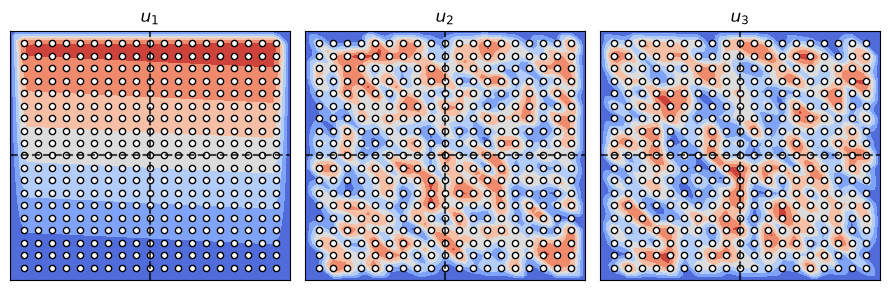

In [46]:
number_of_solutions = 3

# each row is an element v_i of the vector space V (dim(V) = 361 columns)
solutions = [np.linspace(0, 1, sm.vspace_dim)]
solutions = np.vstack((solutions, np.random.uniform(size=(number_of_solutions - 1, sm.vspace_dim))))
print("Solutions: \n", solutions)
print("Shape: \n", np.shape(solutions))

x, y = np.meshgrid(sm.points_r[1:-1], sm.points_c[1:-1])
points = np.concatenate([x.reshape((-1, 1)), y.reshape((-1, 1))], axis=1)
evaluations = sm.evaluate_solutions(points=points, solutions=solutions)
print("Number of points: ", len(points))
print("Evaluations: \n", evaluations)

plot_solutions_together(
    sm,
    diffusion_coefficients=None,
    solutions=solutions,
    num_points_per_dim_to_plot=50,
    contour_levels=7,
    axes_xy_proportions=(3, 3),
    titles=[rf"$u_{i + 1}$" for i in range(number_of_solutions)],
    colorbar=False,
    measurement_points=points)

##### **sm.generate_solutions**

Diffusion coefficients shape:  (3, 2, 2) = (number_of_solutions, ) + (2, 2)
Solutions shape:  (3, 361)


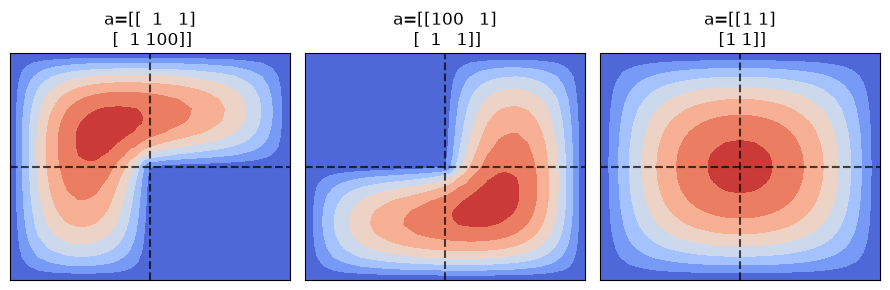

In [47]:
number_of_solutions = 3
number_of_points = 100

# define the matrix of diffusion coefficients \theta for each solution u to be computed.
diffusion_coefficients = np.array([
    [[1, 1],
     [1, 100]],

    [[100, 1],
     [1, 1]],

    [[1, 1],
     [1, 1]],
])
print("Diffusion coefficients shape: ", np.shape(diffusion_coefficients),
      f"= (number_of_solutions, ) + {sm.blocks_geometry}")

# generate as many solutions as diffusion coefficients matrices given
u = sm.generate_solutions(theta=diffusion_coefficients[:, ::-1])
print("Solutions shape: ", np.shape(u))
plot_solutions_together(
    sm,
    diffusion_coefficients=np.array(diffusion_coefficients),
    solutions=u,
    num_points_per_dim_to_plot=50,
    contour_levels=7,
    axes_xy_proportions=(3, 3),
    titles=[r"$u_{}$".format(i) for i in range(number_of_solutions)],
    colorbar=False,
    measurement_points=None)